In [36]:
import os
import json
import pickle
import geopandas as gpd
import matplotlib.pyplot as plt
from tqdm import tqdm
from PIL import Image

In [47]:
all_distances = []
gt = os.listdir('/data/aiclinic/pathways/pathwaybench_seattle/pairs/')
for file in tqdm(gt):
    with open(f'/data/aiclinic/pathways/pathwaybench_seattle/pairs/{file}/graph.pickle', 'rb') as f:
        G = pickle.load(f)
    all_distances+=[math.dist(edge[0], edge[1]) for edge in list(G.edges)]
np.quantile(all_distances, 0.25), np.median(all_distances), np.mean(all_distances), np.quantile(all_distances, 0.75)

100%|██████████| 347/347 [00:00<00:00, 7235.19it/s]


(np.float64(0.0225485719917497),
 np.float64(0.05861153811324191),
 np.float64(0.0802627816586852),
 np.float64(0.14235343374854012))

In [49]:
all_distances = []
gt = os.listdir('/data/aiclinic/pathways/generation_full_data/pairs/')
gt.remove('.DS_Store')
for file in tqdm(gt):
    with open(f'/data/aiclinic/pathways/generation_full_data/pairs/{file}/graph.pickle', 'rb') as f:
        G = pickle.load(f)
    all_distances+=[math.dist(edge[0], edge[1]) for edge in list(G.edges)]
np.quantile(all_distances, 0.25), np.median(all_distances), np.mean(all_distances), np.quantile(all_distances, 0.75)

100%|██████████| 2858/2858 [00:00<00:00, 11674.34it/s]


(np.float64(0.03546364335148701),
 np.float64(0.12311315932913106),
 np.float64(0.1031788357541449),
 np.float64(0.1522587934875874))

In [2]:
gt = os.listdir('/data/aiclinic/pathways/pathwaybench_seattle/pairs/')
preds = os.listdir('/data/models/bin/2026_pathway_generation/predictions_seattle/swin_tiny/grpo/seed_0')

In [32]:
idx = 100
with open(f'/data/aiclinic/pathways/generation_full_data/pairs/{idx}/bbox.json', 'r') as f:
    bbox = json.load(f)['bbox']
with open(f'/data/aiclinic/pathways/generation_full_data/pairs/{idx}/graph.pickle', 'rb') as f:
    G = pickle.load(f)

In [33]:
distances = [math.dist(edge[0], edge[1]) for edge in list(G.edges)]
np.mean(distances), np.median(distances)

(np.float64(0.10391877632313594), np.float64(0.13183102669705637))

In [3]:
file = gt[1]
with open(f'/data/aiclinic/pathways/pathwaybench_seattle/pairs/{file}/bbox.json', 'r') as f:
    bbox = json.load(f)['bbox']
with open(f'/data/aiclinic/pathways/pathwaybench_seattle/pairs/{file}/graph.pickle', 'rb') as f:
    G = pickle.load(f)
img = Image.open(f'/data/aiclinic/pathways/pathwaybench_seattle/pairs/{file}/satellite.png')
prd = gpd.read_file(f'/data/models/bin/2026_pathway_generation/predictions_seattle/swin_tiny/grpo/seed_0/{file}_seed0_pred.geojson')
prd.shape

(59, 1)

In [7]:
bbox

[-122.33953429616179,
 -122.33805470383822,
 47.615300304351976,
 47.616297695648015]

In [21]:
import math
import numpy as np

In [22]:
distances = [math.dist(edge[0], edge[1]) for edge in list(G.edges)]

In [25]:
np.mean(distances), np.median(distances)

(np.float64(0.08554756132490514), np.float64(0.049067636992217174))

In [6]:
list(G.edges)

[((0.16363, 0.0), (0.27866, 0.1301)),
 ((0.27866, 0.1301), (0.39369, 0.26021)),
 ((0.39369, 0.26021), (0.50872, 0.39031)),
 ((0.50872, 0.39031), (0.47195, 0.4228)),
 ((0.50872, 0.39031), (0.52338, 0.40174)),
 ((0.37321, 0.50822), (0.33495, 0.44576)),
 ((0.37321, 0.50822), (0.39173, 0.49208)),
 ((0.37321, 0.50822), (0.39227, 0.5393)),
 ((0.37321, 0.50822), (0.22871, 0.63365)),
 ((0.33495, 0.44576), (0.29481, 0.38891)),
 ((0.29481, 0.38891), (0.18907, 0.27366)),
 ((0.18907, 0.27366), (0.08333, 0.15841)),
 ((0.08333, 0.15841), (0.0636, 0.12753)),
 ((0.0636, 0.12753), (0.0, 0.0576)),
 ((0.47195, 0.4228), (0.44978, 0.44235)),
 ((0.44978, 0.44235), (0.40504, 0.48195)),
 ((0.40504, 0.48195), (0.39173, 0.49208)),
 ((0.39227, 0.5393), (0.40207, 0.54943)),
 ((0.40207, 0.54943), (0.45127, 0.60608)),
 ((0.22871, 0.63365), (0.22175, 0.6516)),
 ((0.45127, 0.60608), (0.46682, 0.62402)),
 ((0.46682, 0.62402), (0.49378, 0.6551)),
 ((0.49378, 0.6551), (0.53656, 0.66473)),
 ((0.0, 0.84743), (0.11087, 0.7

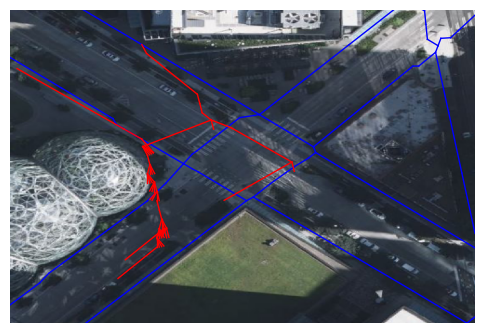

In [8]:
min_lon, max_lon, min_lat, max_lat = bbox
dx = max_lon - min_lon
dy = max_lat - min_lat
def denorm(p):
    x, y = p
    lon = min_lon + x * dx
    lat = min_lat + y * dy
    return lon, lat
    
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(min_lon, max_lon)
ax.set_ylim(min_lat, max_lat)
ax.axis("off")
ax.imshow(img, extent=bbox)
for u, v in G.edges():
    # nodes may be tuples already, but support 'pos' attribute too
    pu = G.nodes[u].get("pos", u)
    pv = G.nodes[v].get("pos", v)
    lon_u, lat_u = denorm(pu)
    lon_v, lat_v = denorm(pv)
    ax.plot([lon_u, lon_v], [lat_u, lat_v], color='blue', linewidth=1)

for geom in prd.geometry: 
    if geom is None: continue 
    if geom.geom_type == "LineString": 
        x, y = geom.xy 
        ax.plot(x, y, color="red", linewidth=1.0) 
    elif geom.geom_type == "MultiLineString": 
        for part in geom.geoms: 
            x, y = part.xy
            ax.plot(x, y, color="red", linewidth=1.0) 
pass